Running graph sampler on 2D map with discrete space and grid nodes...
Generated 5294 nodes in 0.059805870056152344 seconds
Generated 20642 road map edges in 0.7373802661895752 seconds


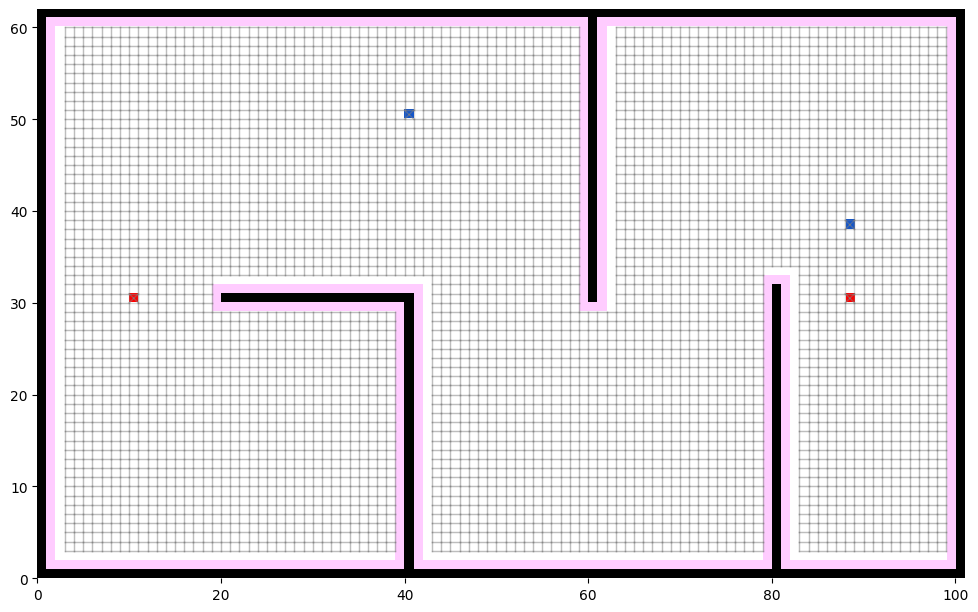

In [2]:
"""
Run graph sampler for 2D and 3D maps.
python scripts/roadmaps/run_graph_sampler.py
"""

from path_planning.common.visualizer.visualizer_2d import Visualizer2D
from path_planning.common.visualizer.visualizer_3d import Visualizer3D
from path_planning.utils.util import read_graph_sampler_from_yaml
from path_planning.utils.util import set_global_seed
from python_motion_planning.common import TYPES
import numpy as np
import os
import time

def run_graph_sampler(graph_sampler,start,goal,generate_grid_nodes = True,sample_num = 1000,num_neighbors = 4.0,min_edge_len = 0.5,max_edge_len = 1.0):
    set_global_seed(42)
    if start is not None:
        graph_sampler.set_start(start)
    if goal is not None:
        graph_sampler.set_goal(goal)
    graph_sampler.set_parameters(sample_num=sample_num, num_neighbors=num_neighbors, min_edge_len=min_edge_len, max_edge_len=max_edge_len)
    
    st = time.time()
    nodes = graph_sampler.generateRandomNodes(generate_grid_nodes = generate_grid_nodes)
    print(f"Generated {len(nodes)} nodes in {time.time() - st} seconds")

    planar_nodes = None
    planar_map = None
    st = time.time()
    road_map = graph_sampler.generate_roadmap(nodes)
    num_edges = sum([len(edges) for edges in road_map])
    print(f"Generated {num_edges} road map edges in {time.time() - st} seconds")

    # if map_.dim == 2:
    #     roadmap_type = 'cdt'
    # else:
    #     roadmap_type = 'dt'
    # st = time.time()
    # planar_map = graph_sampler.generate_planar_map(nodes, use_option=roadmap_type)
    # planar_nodes = graph_sampler.nodes
    # num_edges = sum([len(edges) for edges in planar_map])   
    # print(f"Generated {num_edges} planar map edges in {time.time() - st} seconds")

    return graph_sampler, nodes, road_map, planar_nodes, planar_map


map_ =read_graph_sampler_from_yaml('path_planning/maps/2d/2d_double.yaml')
map_.inflate_obstacles(radius=3)
start = [(10,30),(88,30)]
goal = [(88,38), (40,50)]

print("Running graph sampler on 2D map with discrete space and grid nodes...")
map_,nodes, road_map, planar_nodes, planar_map = run_graph_sampler(map_,start,goal,sample_num = 0)
vis = Visualizer2D()
vis.plot_grid_map(map_)
vis.plot_road_map(map_,nodes,road_map)
vis.show()
vis.close()

# vis = Visualizer2D()
# vis.plot_grid_map(map_)
# vis.plot_road_map(map_,planar_nodes,planar_map)

# map_ =read_graph_sampler_from_yaml('path_planning/maps/2d/2d.yaml',use_discrete_space=False)
# map_.inflate_obstacles(radius=3)
# start = [(5,15),(44,15)]
# goal = [(44,19), (20,25)]
# print("Running graph sampler on 2D map with continuous space and random sampling nodes...")
# map_,nodes, road_map, planar_nodes, planar_map = run_graph_sampler(map_,start,goal,sample_num = 1000,generate_grid_nodes=False)
# vis = Visualizer2D()
# vis.plot_grid_map(map_)
# vis.plot_road_map(map_,nodes,road_map,map_frame=False)

# vis = Visualizer2D()
# vis.plot_grid_map(map_)
# vis.plot_road_map(map_,planar_nodes,planar_map,map_frame=False)




In [10]:
import random
random.seed(0)

import numpy as np
np.random.seed(0)
import yaml
from pathlib import Path

from python_motion_planning.common import *
from python_motion_planning.path_planner import *
from python_motion_planning.controller import *

from path_planning.common.visualizer.visualizer_2d import Visualizer2D

map_ = Grid(bounds=[[0, 101], [0, 62]])
map_.fill_boundary_with_obstacles()
map_.type_map[20:41, 30] = TYPES.OBSTACLE
map_.type_map[40, :30] = TYPES.OBSTACLE
map_.type_map[60, 30:] = TYPES.OBSTACLE
map_.type_map[80, :32] = TYPES.OBSTACLE

# Save map to YAML (same contract as path_planning/maps/2d/2d.yaml: world-frame obstacle centers)
obstacle_indices = np.stack(np.where(map_.type_map.data == TYPES.OBSTACLE)).T
obstacles = [
    [float(x) for x in np.asarray(map_.map_to_world(tuple(int(v) for v in idx))).reshape(-1)]
    for idx in obstacle_indices
]
yaml_path = Path("path_planning/maps/2d/2d_double.yaml")
yaml_path.parent.mkdir(parents=True, exist_ok=True)
with open(yaml_path, "w") as f:
    yaml.dump(
        {
            "map": {
                "dimensions": [int(x) for x in map_.shape],
                "bounds": np.asarray(map_.bounds, dtype=float).tolist(),
                "resolution": float(map_.resolution),
                "obs_size": 1.0,
                "obstacles": obstacles,
            },
            "agents": [],
        },
        f,
        default_flow_style=False,
        sort_keys=False,
        allow_unicode=True,
    )
print(f"Wrote {yaml_path.resolve()} ({len(obstacles)} obstacle cells)")

vis = Visualizer2D()
vis.plot_grid_map(map_)
vis.show()

Wrote /home/bho36/Documents/Path-Planning/path_planning/maps/2d/2d_double.yaml (434 obstacle cells)


Roadmap: 816 nodes, 4813 edges in 0.15s
CTopPRM: 1.01s, seeds 16 -> 100 clusters


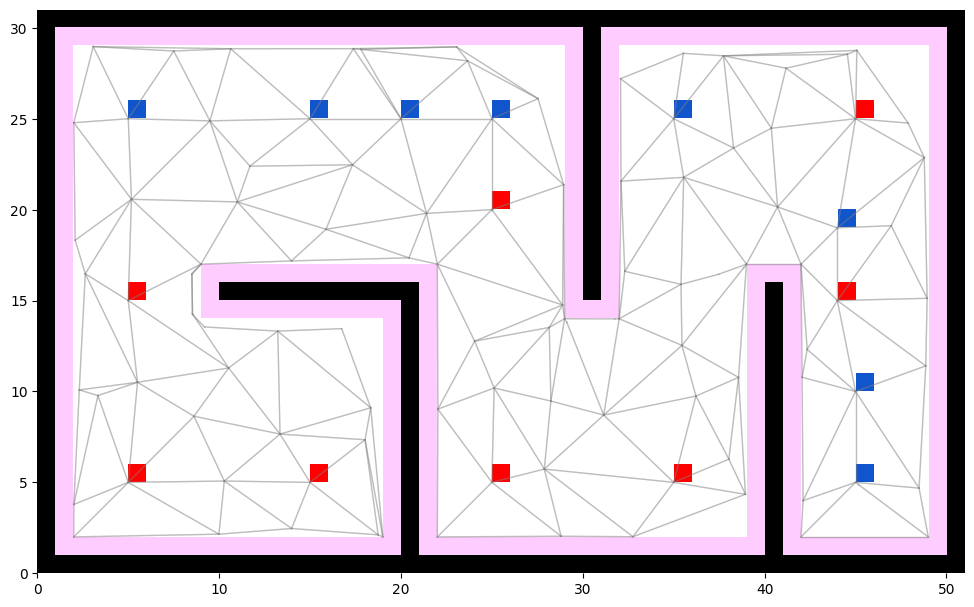

CTopPRM: 0.06s, seeds 16 -> 100 clusters


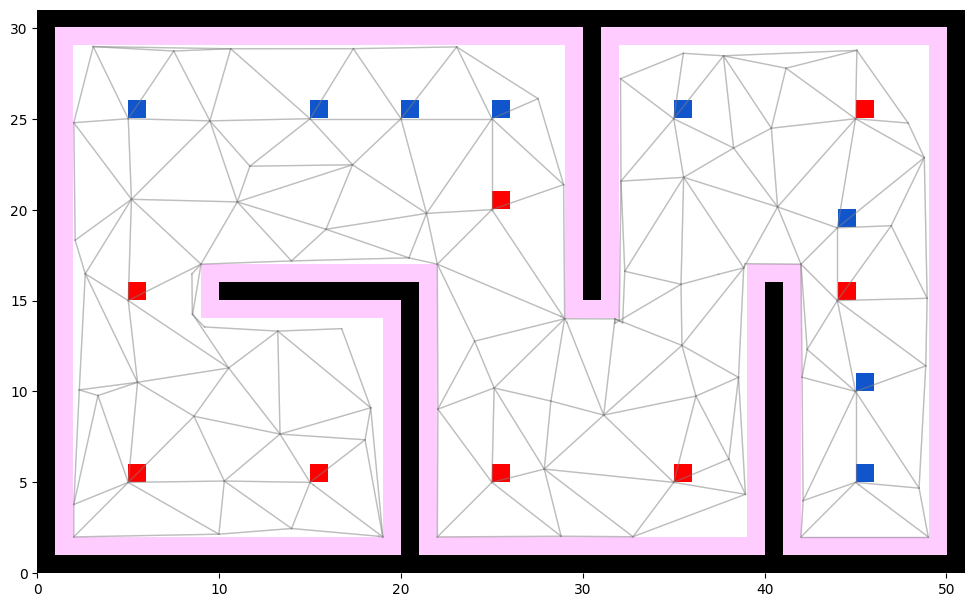

CTopPRM: 0.03s, seeds 16 -> 100 clusters


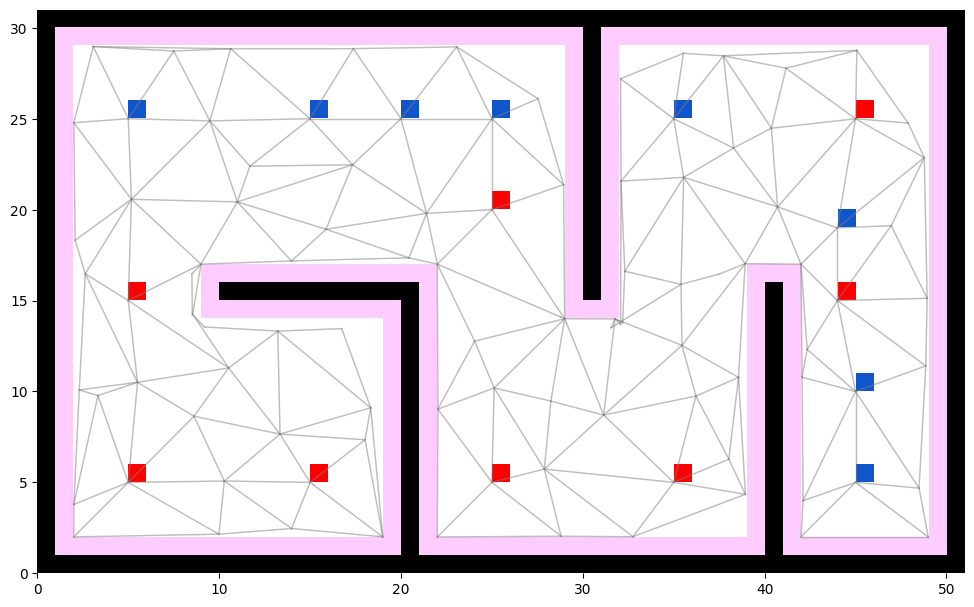

In [6]:
from typing import Any
import time
from path_planning.cluster.CTopPRMpy.ctopprm import CTopPRM
from path_planning.common.visualizer.visualizer_2d import Visualizer2D
from path_planning.utils.util import (
    agents_yaml_to_roadmap_frame,
    read_agents_for_map,
    read_graph_sampler_from_yaml,
    set_global_seed,
)

MAP_YAML = 'path_planning/maps/2d/2d_8agents.yaml'
OUT_DIR = 'figs/ctopprm'

set_global_seed(42)

# Continuous mode keeps every node in world floats, the cleanest frame
# for CTopPRM's continuous-space shortening/homotopy checks.
map_ = read_graph_sampler_from_yaml(MAP_YAML, use_discrete_space=False)
map_.inflate_obstacles(radius=1)
agents = read_agents_for_map(MAP_YAML)
agents = agents_yaml_to_roadmap_frame(map_, agents)

starts = [tuple(a['start']) for a in agents]
goals = [tuple(a['goal']) for a in agents]
map_.set_start(starts)
map_.set_goal(goals)
map_.set_parameters(sample_num=800, num_neighbors=13, min_edge_len=1e-10, max_edge_len=8.0)

st = time.time()
nodes = map_.generateRandomNodes(generate_grid_nodes=False)
road_map = map_.generate_planar_map(nodes)
num_edges = sum(len(e) for e in road_map)
print(f"Roadmap: {len(nodes)} nodes, {num_edges} edges in {time.time() - st:.2f}s")


# All ordered start/goal pairs from agent starts and goals.
starts_goals = starts + goals
pairs = list(zip(starts, goals)) + [(starts[0], goals[1])]

for clustering_name in ["wavefront","em", "kmeans"]:
    planner = CTopPRM(map_, clustering=clustering_name, max_path_length_ratio=2.2,
                    cutoff_distance_ratio_to_shortest=2.0, min_clusters=100,force_min_clusters=True)

    st = time.time()
    resolved, budgets = planner.set_up_distinct_paths(pairs)
    # results = planner.find_distinct_paths(pairs)
    num_initial_seeds = len(set(starts + goals))
    print(f"CTopPRM: {time.time() - st:.2f}s, seeds {num_initial_seeds} -> "
            f"{len(planner.seed_indices)} clusters")

    # --- clusters figure ---
    map_ = read_graph_sampler_from_yaml(MAP_YAML, use_discrete_space=False)
    map_.inflate_obstacles(radius=1)
    agents = read_agents_for_map(MAP_YAML)
    agents = agents_yaml_to_roadmap_frame(map_, agents)

    starts = [tuple(a['start']) for a in agents]
    goals = [tuple(a['goal']) for a in agents]
    map_.set_start(starts)
    map_.set_goal(goals)
    points, edges = planner.get_roadmap()
    map_.generate_custom_nodes(points)
    map_.generate_custom_roadmap(edges)
    vis = Visualizer2D()
    vis.plot_grid_map(map_)
    vis.plot_road_map(map_, map_.nodes, map_.road_map, map_frame=False)
    vis.show()

[Node((0.025, 0.025), None, 0, 0), Node((0.025, 0.07500000000000001), None, 0, 0), Node((0.025, 0.125), None, 0, 0), Node((0.025, 0.17500000000000002), None, 0, 0), Node((0.025, 0.225), None, 0, 0), Node((0.025, 0.275), None, 0, 0), Node((0.025, 0.325), None, 0, 0), Node((0.025, 0.375), None, 0, 0), Node((0.025, 0.42500000000000004), None, 0, 0), Node((0.025, 0.47500000000000003), None, 0, 0), Node((0.025, 0.525), None, 0, 0), Node((0.025, 0.5750000000000001), None, 0, 0), Node((0.025, 0.625), None, 0, 0), Node((0.025, 0.675), None, 0, 0), Node((0.025, 0.7250000000000001), None, 0, 0), Node((0.025, 0.775), None, 0, 0), Node((0.025, 0.8250000000000001), None, 0, 0), Node((0.025, 0.875), None, 0, 0), Node((0.025, 0.925), None, 0, 0), Node((0.025, 0.9750000000000001), None, 0, 0), Node((0.07500000000000001, 0.025), None, 0, 0), Node((0.07500000000000001, 0.07500000000000001), None, 0, 0), Node((0.07500000000000001, 0.125), None, 0, 0), Node((0.07500000000000001, 0.17500000000000002), None

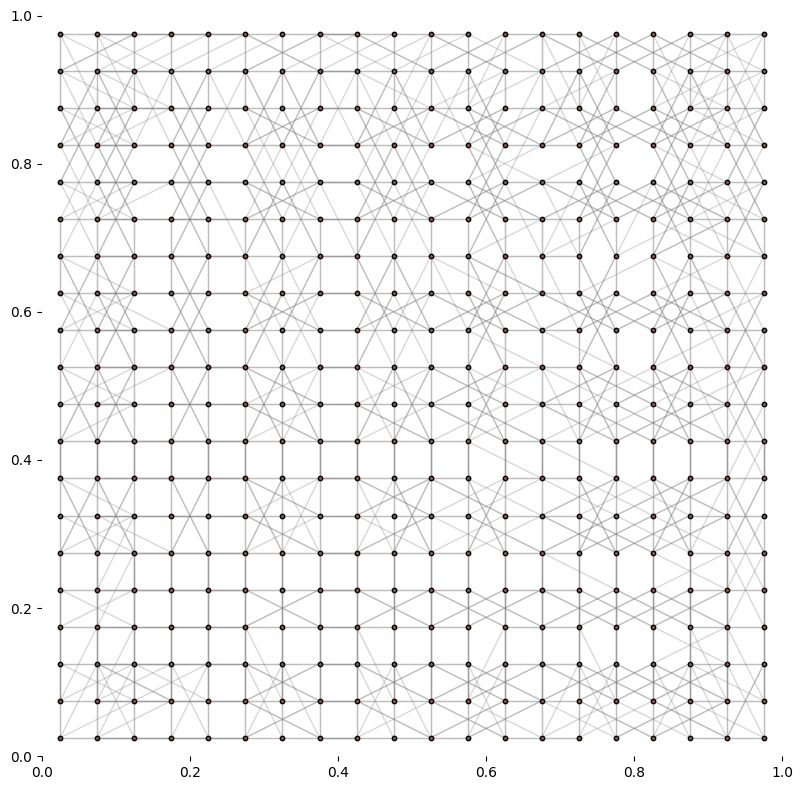

In [22]:
from typing import Any
import time
import numpy as np
from path_planning.cluster.CTopPRMpy.ctopprm import CTopPRM
from path_planning.common.visualizer.visualizer_2d import Visualizer2D
from path_planning.utils.util import (
    agents_yaml_to_roadmap_frame,
    read_agents_for_map,
    read_graph_sampler_from_yaml,
    set_global_seed,
)
from path_planning.common.environment.map.graph_sampler import GraphSampler
from python_motion_planning.common import TYPES

MAP_YAML = 'path_planning/maps/2d/2d_8agents.yaml'
OUT_DIR = 'figs/ctopprm'

set_global_seed(42)

# Continuous mode keeps every node in world floats, the cleanest frame
# for CTopPRM's continuous-space shortening/homotopy checks.
# map_ = read_graph_sampler_from_yaml(MAP_YAML, use_discrete_space=False)


resolution = .05
radius = 1.0

map_ = GraphSampler(bounds=[[0,1],[0,1]], resolution=resolution,start=[],goal=[],use_discrete_space=True)
# map_.fill_boundary_with_obstacles()
# center = [4,4]
# map_.set_obstacles([center])
# num_cell_width = int(np.ceil(1/resolution))
# center_tf = map_.world_to_map(center)
# for i in range(center_tf[0], center_tf[0]+num_cell_width):   
#     for j in range(center_tf[1], center_tf[1]+num_cell_width):
#         map_[i, j] = TYPES.OBSTACLE

# map_.inflate_obstacles(radius=radius)
map_.set_parameters(sample_num=0, num_neighbors=4, min_edge_len=.1, max_edge_len=1.1)
nodes = map_.generateRandomNodes(generate_grid_nodes = True)
print(nodes)
road_map = map_.generate_roadmap(nodes)
print(len(map_.nodes))
vis = Visualizer2D()
vis.plot_grid_map(map_)
vis.plot_road_map(map_, nodes, road_map, map_frame=False,node_size=10)
vis.show()
